# Neighbors and short-range order: occupational and displacement correlations

How ordered is a disordered crystal? This notebook measures local order directly from atomic
positions and species, on small models whose answers are known in advance:

1. **Neighbor lists** — finding every neighbor of every site up to a cutoff, grouping them into
   distance shells (fcc: 12, 6, 24, 12 neighbors), naming individual neighbor vectors the way DISCUS
   does, and doing the same in a skewed (triclinic) cell.
2. **Occupational short-range order** — Warren–Cowley parameters for a binary bcc alloy with perfect
   B2 (CsCl-type) order, partial order and no order, with the standard error a random crystal of
   this size would show; and why the value depends on whether the two sublattices are pooled.
3. **Displacement correlations** — a displacement wave whose correlation between neighbors is a known
   cosine, compared with the computed values, plus the full displacement covariance matrix.
4. **Agreement with DISCUS** — the same quantities computed by DISCUS `chem corr`, re-checked from the
   engine logs committed in the repository.

Every number shown is computed in the notebook. Definitions and conventions:
[`docs/NEIGHBORS.md`](../docs/NEIGHBORS.md), [`docs/CORRELATIONS.md`](../docs/CORRELATIONS.md).

In [1]:
from pathlib import Path
import math
import os
import sys
sys.path.insert(0, str(Path.cwd().parent))
os.chdir(Path.cwd().parent)

import numpy as np
import matplotlib.pyplot as plt
from discuspdf import Lattice, Structure, neighbor_list
from discuspdf.correlations import (
    occupational_correlation, occupational_correlation_table, concentrations,
    displacement_correlation, displacement_correlation_table,
)

def cell(kind, species, a=4.0):
    base = {"sc": [[0, 0, 0]],
            "bcc": [[0, 0, 0], [0.5, 0.5, 0.5]],
            "fcc": [[0, 0, 0], [0.5, 0.5, 0], [0.5, 0, 0.5], [0, 0.5, 0.5]]}[kind]
    return Structure(Lattice.from_parameters(a, a, a, 90, 90, 90), np.array(species, object), base,
                     model="configuration", site_label=[f"S{k + 1}" for k in range(len(base))])

## 1. Neighbor lists

An fcc crystal, 6×6×6 cells (864 atoms). The list holds every directed site pair up to the cutoff,
including all periodic images. Shells are grouped by distance; the coordination numbers are the
textbook 12, 6, 24, 12.

In [2]:
fcc = cell("fcc", ["Cu"] * 4, a=3.6).repeat((6, 6, 6))
nl = neighbor_list(fcc, 5.2)
print(nl)
for sh in nl.shells():
    print(f"shell {sh.index}: d = {sh.distance:.4f} Å   coordination {sh.coordination:g}")

NeighborList(n_nodes=864, n_pairs=46656, cutoff=5.2 Å, pbc=(True, True, True))
shell 1: d = 2.5456 Å   coordination 12
shell 2: d = 3.6000 Å   coordination 6
shell 3: d = 4.4091 Å   coordination 24
shell 4: d = 5.0912 Å   coordination 12


Each pair also carries the **parent-cell translation**, the DISCUS way of naming a neighbor
(`set vec, n, is1, is2, dx, dy, dz`). Here: the first neighbors of site S1 on site S2, by translation.

In [3]:
first = nl.select(shell=1, origin_site="S1", target_site="S2")
vectors, counts = np.unique(first.translation, axis=0, return_counts=True)
for t, c in zip(vectors, counts):
    print("translation", tuple(int(x) for x in t), "pairs", c)

translation (-1, -1, 0) pairs 216
translation (-1, 0, 0) pairs 216
translation (0, -1, 0) pairs 216
translation (0, 0, 0) pairs 216


The same machinery works in any cell. A triclinic lattice with one atom per cell: the shells are
checked in the tests against an independent brute-force enumeration.

In [4]:
tri = Structure(Lattice.from_parameters(3.0, 3.4, 4.1, 72, 84, 107), np.array(["X"], object), [[0, 0, 0]],
                model="configuration").repeat((4, 4, 4))
for sh in neighbor_list(tri, 5.0).shells()[:6]:
    print(f"d = {sh.distance:.4f} Å   coordination {sh.coordination:g}")

d = 3.0000 Å   coordination 2
d = 3.4000 Å   coordination 2
d = 3.8204 Å   coordination 2
d = 4.1000 Å   coordination 2
d = 4.4446 Å   coordination 2
d = 4.4965 Å   coordination 2


## 2. Occupational correlations

A binary A/B alloy on a bcc lattice (8×8×8 cells, 1024 atoms) in three states:

* **ordered** — B2 (CsCl) order: all A on site S1, all B on S2;
* **partially ordered** — the same with 15 % of the atoms swapped between the two sites;
* **random** — every site A or B with probability ½.

For the B2 structure the Warren–Cowley parameter α(A,B) is −1 in the first shell (every
neighbor unlike) and +1 in the second (every neighbor alike).

In [5]:
ref = cell("bcc", ["A", "A"], a=3.0).repeat((8, 8, 8))
on_s1 = ref.site_label == "S1"
rng = np.random.default_rng(2026)

ordered = np.where(on_s1, "A", "B")
partial = ordered.copy()
swap = rng.random(ref.n_atoms) < 0.15
partial[swap] = np.where(partial[swap] == "A", "B", "A")
random_ = np.where(rng.random(ref.n_atoms) < 0.5, "A", "B")
configs = {name: ref.replace(species=s.astype(object))
           for name, s in [("ordered", ordered), ("partial", partial), ("random", random_)]}

nl_bcc = neighbor_list(ref, 6.0)
print(concentrations(nl_bcc, configs["partial"])["by_site"])

{'S1': {'A': 0.876953125, 'B': 0.123046875}, 'S2': {'A': 0.140625, 'B': 0.859375}}


Shell-averaged α(A,B) with its null-model standard error (how far a *random* crystal of this
size would scatter around zero):

In [6]:
rows = {name: [r for r in occupational_correlation_table(nl_bcc, cfg, by="shell") if r["a"] == "A" and r["b"] == "B"]
        for name, cfg in configs.items()}
print(f"{'shell':>5} {'d (Å)':>7}" + "".join(f"{n:>22}" for n in configs))
for k in range(len(rows["ordered"])):
    line = f"{rows['ordered'][k]['shell']:>5} {rows['ordered'][k]['distance']:7.3f}"
    for n in configs:
        r = rows[n][k]
        line += f"   {r['warren_cowley']:+.4f} ± {r['stderr_warren_cowley']:.4f}"
    print(line)

shell   d (Å)               ordered               partial                random
    1   2.598   -1.0000 ± 0.0156   -0.5395 ± 0.0156   -0.0033 ± 0.0156
    2   3.000   +1.0000 ± 0.0180   +0.5389 ± 0.0180   +0.0104 ± 0.0180
    3   4.243   +1.0000 ± 0.0128   +0.5350 ± 0.0128   -0.0066 ± 0.0128
    4   4.975   -1.0000 ± 0.0090   -0.5425 ± 0.0090   -0.0001 ± 0.0090
    5   5.196   +1.0000 ± 0.0156   +0.5311 ± 0.0156   -0.0151 ± 0.0156
    6   6.000   +1.0000 ± 0.0180   +0.5402 ± 0.0180   -0.0027 ± 0.0180


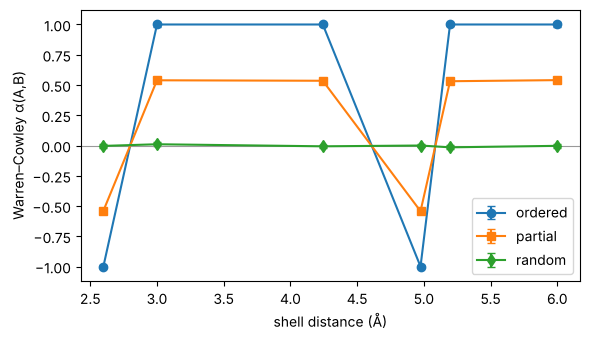

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for name, marker in zip(configs, "osd"):
    d = [r["distance"] for r in rows[name]]
    a = [r["warren_cowley"] for r in rows[name]]
    e = [r["stderr_warren_cowley"] for r in rows[name]]
    ax.errorbar(d, a, yerr=e, marker=marker, capsize=3, label=name)
ax.axhline(0, color="0.6", lw=0.8)
ax.set_xlabel("shell distance (Å)")
ax.set_ylabel("Warren–Cowley α(A,B)")
ax.legend()
fig.tight_layout()

The partially ordered crystal keeps the alternating sign with a reduced magnitude. With an
antisite fraction x on each sublattice and no other correlation, |α| = (1 − 2x)²; the realised
x ≈ 0.13 (see the concentrations above) gives 0.55, as observed. The random crystal stays within
about two standard errors of zero.

**Signed vectors and sublattices.** `by="vector"` resolves each shell into its neighbor vectors
(origin site, target site, translation). Such a selection runs from one sublattice to another, and α
is measured against the concentrations **on that target sublattice**. B2 order is a difference in
sublattice occupation, so it is already contained in those concentrations, and the sublattice-resolved
α is zero for the perfectly ordered crystal (P(B|A) = c_t(B) = 1) and close to zero for the partially
ordered one, whose antisites were placed independently. The shell average above pools both
sublattices, so there the same order shows up as α = ±0.54.

In [8]:
partial = configs["partial"]
sel = nl_bcc.select(shell=1)
by_vector = [r for r in occupational_correlation_table(sel, partial, by="vector") if r["a"] == "A" and r["b"] == "B"]
for r in by_vector[:4]:
    print(r["origin_site"], "->", r["target_site"], r["translation"],
          f"α = {r['warren_cowley']:+.4f} ± {r['stderr_warren_cowley']:.4f}   pairs {r['n_pairs']}")
both = occupational_correlation(sel.select(origin_site="S1", target_site="S2", translation=(0, 0, 0), symmetric=True), partial)
print("same vector, both directions pooled: α(A,B) =", round(both.value("warren_cowley", "A", "B"), 4))

S1 -> S2 (-1, -1, -1) α = +0.0048 ± 0.0067   pairs 512
S1 -> S2 (-1, -1, 0) α = +0.0100 ± 0.0067   pairs 512
S1 -> S2 (-1, 0, -1) α = -0.0030 ± 0.0067   pairs 512
S1 -> S2 (-1, 0, 0) α = +0.0022 ± 0.0067   pairs 512
same vector, both directions pooled: α(A,B) = -0.5513


## 3. Displacement correlations

A simple-cubic crystal (16×4×4 cells) with a longitudinal displacement wave
u_x(R) = A cos(2π·2·n_a/16). For a neighbor vector t = (k, 0, 0) the displacement correlation along
x is exactly cos(2π·2·k/16); along b (t = (0, 1, 0)) it is 1.

max |computed − cos(2π·2k/16)| = 1.8369701987208695e-16


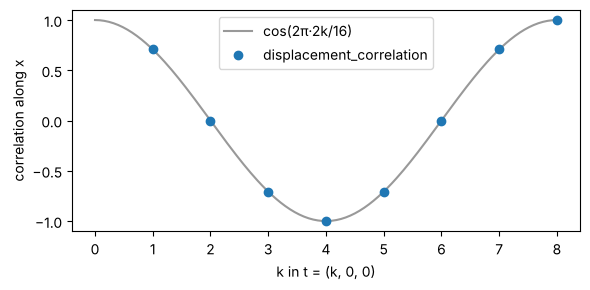

In [9]:
sc = cell("sc", ["Cu"], a=3.0).repeat((16, 4, 4))
phase = 2 * np.pi * 2 * sc.cell_index[:, 0] / 16
wave = sc.with_cartesian(sc.cartesian + 0.05 * np.column_stack([np.cos(phase), np.zeros_like(phase), np.zeros_like(phase)]))
nl_sc = neighbor_list(sc, 8 * 3.0 + 0.1)        # list built on the undisplaced reference
rows = displacement_correlation_table(nl_sc.select(target_site="S1"), wave, direction=(1, 0, 0), by="vector")
along_a = sorted((r["translation"][0], r["correlation"]) for r in rows
                 if r["translation"][1:] == (0, 0) and r["translation"][0] > 0)
k = np.array([t for t, _ in along_a])
c = np.array([v for _, v in along_a])
print("max |computed − cos(2π·2k/16)| =", np.max(np.abs(c - np.cos(2 * np.pi * 2 * k / 16))))

fig, ax = plt.subplots(figsize=(6, 3))
kk = np.linspace(0, 8, 200)
ax.plot(kk, np.cos(2 * np.pi * 2 * kk / 16), color="0.6", label="cos(2π·2k/16)")
ax.plot(k, c, "o", label="displacement_correlation")
ax.set_xlabel("k in t = (k, 0, 0)")
ax.set_ylabel("correlation along x")
ax.legend()
fig.tight_layout()

Without a direction, `displacement_correlation` still returns the full 3×3 covariance of origin and
target displacements. For t = (1, 0, 0) only the xx element is nonzero: A²/2 · cos(π/4) = 8.8 × 10⁻⁴ Å².
The y and z displacements are exactly zero here, so their correlations are undefined (NaN).

In [10]:
res = displacement_correlation(nl_sc.select(translation=(1, 0, 0), symmetric=True), wave)
np.set_printoptions(precision=6, suppress=True)
print("covariance (Å²):\n", res.covariance)
print("correlation matrix:\n", res.correlation_matrix)

covariance (Å²):
 [[0.000884 0.       0.      ]
 [0.       0.       0.      ]
 [0.       0.       0.      ]]
correlation matrix:
 [[0.707107      nan      nan]
 [     nan      nan      nan]
 [     nan      nan      nan]]


## 4. Comparison with DISCUS `chem corr`

`discuspdf` reproduces DISCUS's own correlation definitions (`OccupationalCorrelation.discus` and
`displacement_correlation(..., reference="site_average", centered=False)`). The engine comparison
in `benchmarks/discus_6_23_01/c_probes/` ran DISCUS 6.23.01 on three crystals; its predictions were
committed before the run. Re-checking the committed logs:

In [11]:
import importlib.util
spec = importlib.util.spec_from_file_location("c_analyze", "benchmarks/discus_6_23_01/c_probes/analyze.py")
analyze = importlib.util.module_from_spec(spec)
spec.loader.exec_module(analyze)
evidence = sorted(Path("benchmarks/discus_6_23_01/c_probes/evidence").iterdir())[-1]
status = analyze.main(evidence)

input SHA-256: 6/6 match
occ_bcc: corr blocks [('occ', 'AU', 'CU'), ('occ', 'CU', 'AU')] (expected [('occ', 'AU', 'CU'), ('occ', 'CU', 'AU')]), complete
occ_bcc  corr occ Au,Cu  #1 vec [1, 2, [0, 0, 0]]                pairs 1024/1024  DISCUS -0.195240774120  ours -0.195240774120  |d| 4.7e-13  OK
occ_bcc  corr occ Au,Cu  #2 vec [1, 2, [-1, -1, -1]]             pairs 1024/1024  DISCUS -0.187403129700  ours -0.187403129700  |d| 3.4e-15  OK
occ_bcc  corr occ Au,Cu  #3 vec [1, 1, [1, 0, 0]]                pairs 512/512  DISCUS +0.041666666667  ours +0.041666666667  |d| 3.3e-14  OK
occ_bcc  corr occ Au,Cu  #4 vec [2, 2, [0, 1, 0]]                pairs 512/512  DISCUS -0.038055082085  ours -0.038055082085  |d| 3.4e-14  OK
occ_bcc  corr occ Au,Cu  #5 vec [2, 1, [1, 0, 1]]                pairs 1024/1024  DISCUS -0.218753707382  ours -0.218753707382  |d| 1.5e-13  OK
occ_bcc  corr occ Au,Cu  #6 dis [[0.5, 0.5, 0.5], 0.1]           pairs 8192/8192  DISCUS -0.186423424147  ours -0.186423424147  |d|

## Things to keep in mind

* **Build the list on the reference, analyse the configuration.** Shells of a displaced crystal are
  blurred; the list's nodes are matched to the configuration's atoms by (site label, cell).
* **DISCUS files:** `read_stru` labels atoms by species, so relabel structures read from `.stru`
  files with `label_sites_by_slot` before comparing configurations.
* **Small supercells:** if a selected vector spans the whole supercell, atoms are paired with their
  own images; the result then reports `n_self_pairs > 0` and no standard error.
* **Standard errors** describe random crystals; they are not confidence intervals for ordered ones.